In [1]:
!pip install sdv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.7/204.7 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.5/140.5 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.3/202.3 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 7.9 MB/s eta 0:00:00


In [2]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 8.4 MB/s eta 0:00:00


In [17]:
import pandas as pd
import numpy as np
import math
import itertools
import matplotlib.pyplot as plt
from sklearn.preprocessing import QuantileTransformer

from sdv.metadata import SingleTableMetadata
from sdv.single_table import TVAESynthesizer
from sdv.evaluation.single_table import evaluate_quality, run_diagnostic
from sdv.cag import FixedCombinations

import torch
import optuna
import gc
import copy

## Input data

In [25]:
train_df = pd.read_parquet("/content/train_df_seed42.parquet")
train_df.head() # check if the file has been read correctly

,Patient_ID,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,223,1,86,31.47,0,3,0,0,1,1,...,0,0,0,0,0,7,1758,545,1,0
1,43,1,75,21.30,2,2,0,0,0,0,...,0,0,0,0,0,39,39,39,1,0
2,214,1,75,25.00,0,3,1,1,1,0,...,0,0,0,0,0,8,797,797,0,0
3,196,1,87,28.13,0,3,1,1,0,0,...,0,0,0,0,0,9,236,77,1,0
4,57,0,78,27.13,0,3,1,1,1,0,...,0,0,0,0,1,6,2066,2066,0,0


In [26]:
test_df = pd.read_parquet("/content/test_df_seed42.parquet")
test_df.head() # check if the file has been read correctly

,Patient_ID,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,2,1,85,34.72,0,3,0,1,1,0,...,0,1,0,0,0,11,235,123,1,0
1,14,1,64,22.21,0,2,0,0,0,0,...,0,0,0,0,0,6,2086,2086,0,0
2,21,0,58,34.96,2,3,0,1,0,0,...,0,0,0,0,0,14,2828,2828,0,0
3,22,0,61,25.40,1,3,1,0,0,0,...,0,0,0,0,0,6,2464,2464,0,0
4,35,1,60,27.30,0,2,1,1,0,0,...,0,0,0,0,0,50,2270,2270,0,0


In [27]:
len_real = math.ceil(len(train_df)*0.2/0.8+len(train_df)) # length of the real database
len_real

353

# Data constraints

To make the synthetic data more realistic, we need to specify certain constraints, e.g. if a patient had not had any chemotherapy, they can't have experienced any side-effect from the medication.

In [28]:
constraints = []

# Cancer staging
constraints.append(FixedCombinations(
    column_names=['T_stage', 'N_stage', 'M_stage', 'TNM_stage']
))

# Chemotherapy
constraints.append(FixedCombinations(column_names=[
        'Adjuvant_CT', 'Early_end_CT', 'CT_toxicity'
    ]))

# Complications
constraints.append(FixedCombinations(column_names=[
    'Anastomosis',
    'Complications',
    'Leak',
    'SSI',
    'Pneumonia',
    'Paralytic_ileus',
    'Kidney_failure'
]))

# Surgery type
constraints.append(FixedCombinations(column_names=[
        'Site', 'Surgery_type'
    ]))

# Metadata

/usr/local/lib/python3.12/dist-packages/sdv/metadata/single_table.py:937: UserWarning: There is an existing primary key 'Patient_ID'. This key will be removed.
  warnings.warn(


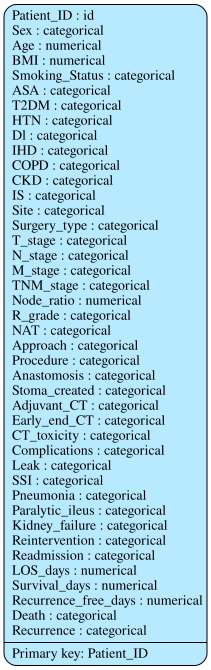

In [29]:
def build_metadata(df: pd.DataFrame, primary_key: str = "Patient_ID") -> SingleTableMetadata:
    metadata = SingleTableMetadata()
    metadata.detect_from_dataframe(df)

    if primary_key in df.columns:
        metadata.update_column(column_name=primary_key, sdtype='id')
        metadata.set_primary_key(primary_key)

    return metadata


metadata = build_metadata(train_df)
metadata.visualize()

# Synthetic data generation with default hyperparameters (Demo)

In [9]:
synthesizer = TVAESynthesizer(
    metadata,
    epochs=300,
    batch_size=500,
    embedding_dim=128,
    compress_dims=(256, 128),
    decompress_dims=(128, 256),
    l2scale=1e-5,
    loss_factor=2,
    verbose=True,
    cuda=False
)

synthesizer.add_constraints(constraints=constraints)

synthesizer.fit(train_df)

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(
Loss: -09.47: 100%|██████████| 300/300 [00:10<00:00, 27.32it/s]


In [11]:
# Sample, then invert transforms to restore original scale
synthetic_table   = synthesizer.sample(num_rows=len_real)

synthetic_table.to_parquet(f"tvae_result_demo.parquet")
synthetic_table.head()

,Patient_ID,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,4458169,1,81,24.05,0,3,1,0,0,0,...,0,0,0,0,0,5,1988,2684,0,0
1,12478745,0,80,24.27,0,2,0,1,0,0,...,0,0,0,0,0,6,802,491,1,0
2,7887661,1,80,26.56,0,3,0,1,0,0,...,0,0,0,0,0,5,864,277,1,1
3,10501117,1,88,21.94,<NA>,3,0,0,0,0,...,0,0,0,0,0,11,3,103,1,1
4,14660754,1,88,23.56,0,2,0,0,0,0,...,0,0,0,0,0,6,2622,2045,0,0


# Hyperparameter optimization

In [23]:
def train_and_evaluate_sdv(train_df_t, test_df_t, metadata_transformed, params, seed=42):
    meta_copy = copy.deepcopy(metadata_transformed)

    synth = TVAESynthesizer(
        meta_copy,
        epochs          = params['epochs'],
        batch_size      = params['batch_size'],
        embedding_dim   = params['embedding_dim'],
        compress_dims   = params['compress_dims'],
        decompress_dims = params['decompress_dims'],
        l2scale         = params['l2scale'],
        loss_factor     = params['loss_factor'],
        verbose         = False,
        cuda            = False,
    )
    synth.add_constraints(constraints=constraints)
    synth.fit(train_df_t)

    synthetic_val = synth.sample(num_rows=10000)

    quality_report = evaluate_quality(
        real_data      = test_df,
        synthetic_data = synthetic_val,
        metadata       = metadata,
        verbose        = False,
    )
    return quality_report.get_score(), synth


def grid_search_sdv(train_df_t, test_df_t, metadata_transformed, param_grid, seed=42):
    keys   = list(param_grid.keys())
    values = list(param_grid.values())
    combos = list(itertools.product(*values))
    print(f"Grid search: {len(combos)} combinations\n")

    results     = []
    best_score  = -1
    best_synth  = None
    best_params = None

    for i, combo in enumerate(combos, 1):
        params = dict(zip(keys, combo))
        print(f"[{i}/{len(combos)}] {params}", end=" → ")

        try:
            score, synth = train_and_evaluate_sdv(
                train_df_t, test_df_t, metadata_transformed, params, seed
            )
            results.append({**params, 'quality_score': score})
            print(f"quality_score = {score:.4f}")

            if score > best_score:
                best_score  = score
                best_synth  = synth
                best_params = params
        except Exception as e:
            print(f"FAILED ({e})")
            results.append({**params, 'quality_score': None})

    results.sort(key=lambda x: (x['quality_score'] is not None, x['quality_score']), reverse=True)
    print(f"\nBest configuration: {results[0]}")
    return best_params, best_synth, results

In [24]:
param_grid = {
    'epochs':          list(range(100,3000,100)),
    'batch_size':      [32, 64],
    'embedding_dim':   [64, 128],
    'compress_dims':   [(128, 64), (256, 128)],
    'decompress_dims': [(64, 128), (128, 256)],
    'l2scale':         [0.001, 0.0005],
    'loss_factor':     [2, 4],
}

best_params, best_synth, all_results = grid_search_sdv(
    train_df, test_df, metadata, param_grid, seed=42
)

pd.DataFrame(all_results).to_csv("grid_search_sdv_results.csv", index=False)

Grid search: 1856 combinations

[1/1856] {'epochs': 100, 'batch_size': 32, 'embedding_dim': 64, 'compress_dims': (128, 64), 'decompress_dims': (64, 128), 'l2scale': 0.001, 'loss_factor': 2} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(


quality_score = 0.8009
[2/1856] {'epochs': 100, 'batch_size': 32, 'embedding_dim': 64, 'compress_dims': (128, 64), 'decompress_dims': (64, 128), 'l2scale': 0.001, 'loss_factor': 4} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(


quality_score = 0.8097
[3/1856] {'epochs': 100, 'batch_size': 32, 'embedding_dim': 64, 'compress_dims': (128, 64), 'decompress_dims': (64, 128), 'l2scale': 0.0005, 'loss_factor': 2} → 

...

quality_score = 0.8147
[10/1856] {'epochs': 100, 'batch_size': 32, 'embedding_dim': 64, 'compress_dims': (256, 128), 'decompress_dims': (64, 128), 'l2scale': 0.001, 'loss_factor': 4} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(


quality_score = 0.8124
[11/1856] {'epochs': 100, 'batch_size': 32, 'embedding_dim': 64, 'compress_dims': (256, 128), 'decompress_dims': (64, 128), 'l2scale': 0.0005, 'loss_factor': 2} → 

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
best_params, best_synth, all_results = grid_search_sdv(
    train_df, test_df, metadata, param_grid, seed=seed
)

In [ ]:
best_params

{'epochs': 1000,
 'batch_size': 64,
 'embedding_dim': 64,
 'compress_dims': (256, 128),
 'decompress_dims': (128, 256),
 'l2scale': 0.0005,
 'loss_factor': 2}

## Generation with the best hyperparameters

In [ ]:
# Re-transform the full dataset and retrain on all available data

best_synth_full = TVAESynthesizer(
    metadata,
    epochs          = best_params['epochs'],
    batch_size      = best_params['batch_size'],
    embedding_dim   = best_params['embedding_dim'],
    compress_dims   = best_params['compress_dims'],
    decompress_dims = best_params['decompress_dims'],
    l2scale         = best_params['l2scale'],
    loss_factor     = best_params['loss_factor'],
    verbose         = True,
    cuda            = False,
)
best_synth_full.add_constraints(constraints=constraints)
best_synth_full.fit(train_df)

synthetic_best  = best_synth_full.sample(num_rows=len_real)

synthetic_best.to_parquet("tvae_result_best.parquet", index=False)
print(f"Synthetic data saved: {len(synthetic_best)} rows")
synthetic_best.head()

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/ctgan/synthesizers/_utils.py:16: FutureWarning: `cuda` parameter is deprecated and will be removed in a future release. Please use `enable_gpu` instead.
  warnings.warn(
Loss: -12.37: 100%|██████████| 1000/1000 [00:57<00:00, 17.33it/s]


Dataset sintético guardado: 354 filas


,ID_Paciente,Sexo,Edad_Cirugia,IMC_def,Estado_Fumador,Clasificacion_ASA,Dm2,Hta,Dl,Cardiopatia_Isquemica,...,Complicacion_ileo_paralitico,Complicacion_insuficiencia_renal,Reintervencion_si,Reingreso_30d_si,Estancia_Dias,Supervivencia_Dias,Libre_Recidiva_Dias,Exitus_def,Recidiva_def,Ratio_ganglios
0,11357329,0,51,21.671709,0.0,2.0,0,0,1,0,...,0,0,0,0,9,2607.024825,278,0,1,0.300218
1,9061013,0,89,24.532434,0.0,4.0,0,1,0,0,...,0,1,1,0,15,295.535708,300,1,0,0.000000
2,5558699,0,65,31.707709,1.0,3.0,1,1,1,1,...,0,0,0,0,7,627.855605,121,1,0,0.666667
3,16069986,1,63,29.254395,0.0,2.0,0,1,1,1,...,0,0,0,0,15,702.626450,735,1,1,0.533310
4,5714206,1,71,26.054303,0.0,3.0,0,0,1,1,...,0,1,1,0,32,2450.144222,2875,1,0,0.000000


In [ ]:
# Save the synthesizer
best_synth_full.save("tvae_best_synthesizer.pkl")
# To load it: synth = TVAESynthesizer.load("tvae_best_synthesizer.pkl")